# LightGBM regression: ATFM delay per arrival

This notebook predicts daily ATFM arrival delay per arrival at 12 German airports (2014–2025, one row per airport-day) with a LightGBM regressor, using the same rows, predictors and benchmarks as the Ridge model in notebook 05. The target `atfm_delay_per_arrival` is total ATFM arrival delay minutes divided by arrivals, so undelayed flights are included; about 89% of days are zero. Data come from `data/processed/airport_day.parquet`, and the 37 predictors are taken from the feature contract in `data/processed/feature_contract.json`. Same-day observed weather is used as a perfect forecast, so this is a retrospective study rather than a tested day-ahead forecast; history columns are assumed to be available at the start of the day, which has not been checked against EUROCONTROL publication times. The standard squared-error objective is compared with a Tweedie objective in section 10.

| Period | Years | Use |
|---|---|---|
| train | 2014–2021 | fitting |
| select | 2022 | model selection, early stopping |
| check | 2023 | second pre-test check, post-processing decisions |
| test | 2024–2025 | final evaluation, scored once |

2024–2025 was looked at in earlier project work, so it is a previously inspected period rather than a fully untouched test set. It is not used for any decision in this notebook.

## 1. Setup

In [1]:
# 1 setup
import platform
from pathlib import Path

import numpy as np
import pandas as pd
import sklearn
import lightgbm as lgb

RANDOM_SEED = 42

# The notebooks live in notebooks/, so the repository root is one level up
PROJECT_ROOT = Path.cwd().parent
DATA_PATH = PROJECT_ROOT / "data" / "processed" / "airport_day.parquet"
CONTRACT_PATH = PROJECT_ROOT / "data" / "processed" / "feature_contract.json"

print("Python:      ", platform.python_version())
print("pandas:      ", pd.__version__)
print("numpy:       ", np.__version__)
print("scikit-learn:", sklearn.__version__)
print("lightgbm:    ", lgb.__version__)
print()
print("Random seed:", RANDOM_SEED)
print("Data file found:    ", DATA_PATH.exists(), "->", DATA_PATH.relative_to(PROJECT_ROOT))
print("Contract file found:", CONTRACT_PATH.exists(), "->", CONTRACT_PATH.relative_to(PROJECT_ROOT))

Python:       3.13.14
pandas:       3.0.3
numpy:        2.4.6
scikit-learn: 1.9.0
lightgbm:     4.6.0

Random seed: 42
Data file found:     True -> data/processed/airport_day.parquet
Contract file found: True -> data/processed/feature_contract.json


Same versions as notebook 05, plus LightGBM 4.6.0. Both input files are present.

## 2. Data checks

In [2]:
# 2.1 load the dataset
airport_days = pd.read_parquet(DATA_PATH)

print("Rows:   ", airport_days.shape[0])
print("Columns:", airport_days.shape[1])

Rows:    52596
Columns: 79


Example rows for Frankfurt (EDDF). Each row is one airport on one UTC calendar day; `arrivals_atfm_delayed_15` counts arrivals with more than 15 minutes of ATFM delay.

In [3]:
# 2.2 a few rows for Frankfurt (EDDF), showing only some of the columns
example_columns = [
    "airport_icao", "airport_name", "date", "arrivals", "atfm_delay_min",
    "arrivals_atfm_delayed_15", "temp_mean_c", "gust_max_ms",
    "disrupted_day", "atfm_delay_per_arrival",
]
frankfurt_rows = airport_days[airport_days["airport_icao"] == "EDDF"]
frankfurt_rows[example_columns].head(3)

,airport_icao,airport_name,date,arrivals,atfm_delay_min,arrivals_atfm_delayed_15,temp_mean_c,gust_max_ms,disrupted_day,atfm_delay_per_arrival
1,EDDF,Frankfurt,2014-01-01 00:00:00+00:00,362.0,0.0,0.0,4.575000,8.0,0,0.0
13,EDDF,Frankfurt,2014-01-02 00:00:00+00:00,560.0,1709.0,50.0,7.429167,15.0,1,3.051786
25,EDDF,Frankfurt,2014-01-03 00:00:00+00:00,564.0,1730.0,50.0,7.704167,NaN,1,3.067376


On 2 January 2014 Frankfurt had 560 arrivals, 50 of them delayed by more than 15 minutes (8.9%, above the 2% threshold), so the day is disrupted; delay per arrival is 1,709 / 560 ≈ 3.05 minutes. The `NaN` gust on 3 January is a real gap in the weather record.

In [4]:
# 2.3 which airports and dates are covered?
coverage = airport_days.groupby(["airport_icao", "airport_name"]).agg(
    rows=("date", "size"),
    first_date=("date", "min"),
    last_date=("date", "max"),
)
calendar_days = (airport_days["date"].max() - airport_days["date"].min()).days + 1

print("Number of airports:", coverage.shape[0])
print("Calendar days from the first to the last date:", calendar_days)
coverage

Number of airports: 12
Calendar days from the first to the last date: 4383


,,rows,first_date,last_date
airport_icao,airport_name,,,
EDDC,Dresden,4383,2014-01-01 00:00:00+00:00,2025-12-31 00:00:00+00:00
EDDF,Frankfurt,4383,2014-01-01 00:00:00+00:00,2025-12-31 00:00:00+00:00
EDDG,Muenster-Osnabrueck,4383,2014-01-01 00:00:00+00:00,2025-12-31 00:00:00+00:00
EDDH,Hamburg,4383,2014-01-01 00:00:00+00:00,2025-12-31 00:00:00+00:00
EDDK,Cologne-Bonn,4383,2014-01-01 00:00:00+00:00,2025-12-31 00:00:00+00:00
EDDL,Duesseldorf,4383,2014-01-01 00:00:00+00:00,2025-12-31 00:00:00+00:00
EDDM,Munich,4383,2014-01-01 00:00:00+00:00,2025-12-31 00:00:00+00:00
EDDN,Nuremberg,4383,2014-01-01 00:00:00+00:00,2025-12-31 00:00:00+00:00
EDDP,Leipzig-Halle,4383,2014-01-01 00:00:00+00:00,2025-12-31 00:00:00+00:00


12 airports with 4,383 rows each, i.e. every day from 1 January 2014 to 31 December 2025 (12 × 4,383 = 52,596 rows, 79 columns).

In [5]:
# 2.4 is any airport-date pair listed more than once?
duplicate_count = airport_days.duplicated(subset=["airport_icao", "date"]).sum()
print("Duplicate airport-date rows:", duplicate_count)

Duplicate airport-date rows: 0


No duplicate airport-days.

The feature contract, written when the dataset was built, lists the approved predictors (`predictor_allowlist`) and the same-day outcomes that must not be used as inputs (`forbidden_same_day_outcomes`).

In [6]:
# 2.5 read the feature contract
import json

with open(CONTRACT_PATH) as contract_file:
    feature_contract = json.load(contract_file)

predictor_columns = feature_contract["predictor_allowlist"]
forbidden_columns = feature_contract["forbidden_same_day_outcomes"]

print("Approved predictors:", len(predictor_columns))
print("Entries in the forbidden list:", len(forbidden_columns), "| unique:", len(set(forbidden_columns)))
print("Contract note:", feature_contract["note"])

Approved predictors: 37
Entries in the forbidden list: 28 | unique: 27
Contract note: Target definition is EUROCONTROL ATFM airport arrival delay (network regulations), not gate/schedule punctuality.


37 approved predictors. The forbidden list has 28 entries but 27 distinct names (`atfm_delay_min` appears twice), which does not matter for the overlap check.

In [7]:
# 2.6 data type and missing values for every approved predictor
predictor_overview = pd.DataFrame({
    "dtype": airport_days[predictor_columns].dtypes.astype(str),
    "missing_rows": airport_days[predictor_columns].isna().sum(),
})
predictor_overview["missing_percent"] = (100 * predictor_overview["missing_rows"] / len(airport_days)).round(2)
predictor_overview

,dtype,missing_rows,missing_percent
airport_icao,string,0,0.00
weekday,Int8,0,0.00
month,Int8,0,0.00
doy_sin,float64,0,0.00
doy_cos,float64,0,0.00
is_weekend,bool,0,0.00
is_public_holiday,bool,0,0.00
temp_mean_c,float64,185,0.35
temp_min_c,float64,185,0.35
temp_max_c,float64,185,0.35


- Airport and calendar columns are complete.
- Weather columns are missing on 0.35–1.57% of rows; visibility and the weather-code columns (fog, thunder, snow, freezing) have the most gaps.
- History columns are missing on less than 0.6% of rows, mostly at the start of the series and after gaps.
- Data types are mixed; the input helper in section 5 converts everything except the airport code to float.

In [8]:
# 2.7 does the dataset's own 'split' column agree with the planned years?
pd.crosstab(airport_days["year"], airport_days["split"])

split,calibrate,model_select,test,train
year,,,,
2014,0,0,0,4380
2015,0,0,0,4380
2016,0,0,0,4392
2017,0,0,0,4380
2018,0,0,0,4380
2019,0,0,0,4380
2020,0,0,0,4392
2021,0,0,0,4380
2022,0,4380,0,0


The dataset's `split` column matches the planned years. 2016, 2020 and 2024 have 4,392 rows because they are leap years.

## 3. Target distribution

Missing targets (no record, or zero arrivals) are excluded rather than set to zero. Very large values are kept, since severe days are the cases of most operational interest. Everything after the missingness count uses the training years only.

In [9]:
# 3.1 missing, infinite and negative target values in every period (counts only)
target_values = airport_days["atfm_delay_per_arrival"].astype("float64")
print("Missing target values: ", target_values.isna().sum())
print("Infinite target values:", np.isinf(target_values).sum())
print("Negative target values:", (target_values < 0).sum())

target_missing = target_values.isna()
missing_rows = airport_days[target_missing].copy()
missing_rows["reason"] = "other"
missing_rows.loc[~missing_rows["eurocontrol_row_present"], "reason"] = "no EUROCONTROL record for that day"
missing_rows.loc[missing_rows["arrivals"] == 0, "reason"] = "zero arrivals (0 / 0 is undefined)"
pd.crosstab(missing_rows["reason"], missing_rows["split"])

Missing target values:  47
Infinite target values: 0
Negative target values: 0


split,model_select,test,train
reason,,,
no EUROCONTROL record for that day,8,0,30
zero arrivals (0 / 0 is undefined),1,1,7


No infinite or negative values. 47 targets are missing: 38 with no EUROCONTROL record and 9 with zero arrivals (0 / 0). These are the same 47 rows that have no label in the classification notebooks, and they are excluded.

In [10]:
# 3.2 from here on, explore the training years only (2014-2021)
training_days = airport_days[(airport_days["year"] <= 2021) & ~target_missing].copy()
training_target = training_days["atfm_delay_per_arrival"].astype("float64")
print("Training rows with a known target:", len(training_days))

# Re-calculate the target from its two ingredients and compare with the stored column
recalculated = training_days["atfm_delay_min"] / training_days["arrivals"]
print("Largest difference from the stored target:", (recalculated - training_target).abs().max())

Training rows with a known target: 35027
Largest difference from the stored target: 0.0


35,027 training rows. `atfm_delay_min / arrivals` reproduces the stored target exactly.

In [11]:
# 3.3 how many training days have zero ATFM delay, and how big are the others?
zero_days = (training_target == 0).sum()
positive_target = training_target[training_target > 0]
print(f"Zero-delay days:     {zero_days} ({zero_days / len(training_target):.1%})")
print(f"Positive-delay days: {len(positive_target)} ({len(positive_target) / len(training_target):.1%})")
print()
print("All training days (minutes per arrival):")
print(training_target.describe(percentiles=[0.5, 0.9, 0.95, 0.99, 0.999]).round(3).to_string())
print()
print("Positive-delay days only:")
print(positive_target.describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99]).round(3).to_string())

Zero-delay days:     31576 (90.1%)
Positive-delay days: 3451 (9.9%)

All training days (minutes per arrival):
count    35027.000
mean         0.192
std          0.992
min          0.000
50%          0.000
90%          0.000
95%          1.142
99%          4.362
99.9%       11.895
max         37.763

Positive-delay days only:
count    3451.000
mean        1.952
std         2.562
min         0.002
25%         0.602
50%         1.162
75%         2.271
90%         4.412
99%        11.916
max        37.763


- 31,576 training days (90.1%) have zero ATFM arrival delay; the median and the 90th percentile are both 0, and the mean is 0.19 minutes per arrival.
- On positive days only, the median is 1.16 minutes, 90% are below 4.4 minutes and the maximum is 37.8 minutes.

In [12]:
# 3.4 the ten largest training values - kept, but worth looking at
largest_days = training_days.sort_values("atfm_delay_per_arrival", ascending=False).head(10).copy()
largest_days["date"] = largest_days["date"].dt.date
largest_days[[
    "airport_icao", "airport_name", "date", "arrivals", "atfm_delay_min", "atfm_delay_per_arrival",
    "delay_weather_min", "delay_atc_capacity_min", "delay_atc_staffing_min", "delay_aerodrome_capacity_min",
]].round(2)

,airport_icao,airport_name,date,arrivals,atfm_delay_min,atfm_delay_per_arrival,delay_weather_min,delay_atc_capacity_min,delay_atc_staffing_min,delay_aerodrome_capacity_min
4321,EDDF,Frankfurt,2014-12-27,358.0,13519.0,37.76,0.0,0.0,0.0,0.0
4326,EDDM,Munich,2014-12-27,333.0,12398.0,37.23,12398.0,0.0,0.0,0.0
23439,EDDH,Hamburg,2019-05-08,216.0,6319.0,29.25,0.0,0.0,0.0,6319.0
19371,EDDH,Hamburg,2018-06-03,47.0,1094.0,23.28,0.0,0.0,0.0,0.0
13261,EDDF,Frankfurt,2017-01-10,494.0,11310.0,22.89,11310.0,0.0,0.0,0.0
2509,EDDF,Frankfurt,2014-07-29,652.0,14216.0,21.8,14216.0,0.0,0.0,0.0
3553,EDDF,Frankfurt,2014-10-24,709.0,15195.0,21.43,15195.0,0.0,0.0,0.0
17269,EDDF,Frankfurt,2017-12-10,427.0,8252.0,19.33,0.0,0.0,0.0,0.0
18428,EDDP,Leipzig-Halle,2018-03-16,111.0,2133.0,19.22,2133.0,0.0,0.0,0.0
19465,EDDF,Frankfurt,2018-06-11,681.0,12872.0,18.9,12872.0,0.0,0.0,0.0


The largest value is Frankfurt on 27 December 2014 (13,519 minutes over 358 arrivals, 37.8 minutes per arrival), coded under a cause not shown here; Munich had almost the same value on that day, coded as weather. Most other extreme days are weather-coded; Hamburg on 8 May 2019 is aerodrome capacity.

Hamburg on 3 June 2018 had only 47 arrivals, so 1,094 minutes became 23.3 minutes per arrival. With so few arrivals the ratio is unstable, and it is not clear from the data whether this was a closure or an incomplete record. All these days are kept.

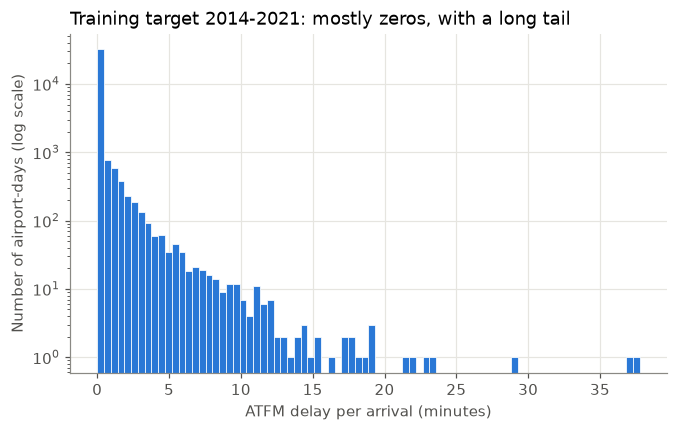

In [13]:
import matplotlib.pyplot as plt

# One consistent, quiet style for every plot in this notebook
plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e6e5e0",
    "axes.edgecolor": "#8a8984",
    "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
})
MODEL_COLOR = "#2a78d6"      # blue: the model
SECOND_COLOR = "#eb6834"     # orange: second line (benchmark or alternative)
THIRD_COLOR = "#1baf7a"      # green: third line
REFERENCE_COLOR = "#8a8984"  # grey: reference lines

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(training_target, bins=80, color=MODEL_COLOR, edgecolor="white", linewidth=0.5)
ax.set_yscale("log")
ax.set_xlabel("ATFM delay per arrival (minutes)")
ax.set_ylabel("Number of airport-days (log scale)")
ax.set_title("Training target 2014-2021: mostly zeros, with a long tail", loc="left")
ax.set_axisbelow(True)
plt.show()

All 31,576 zero-delay training days fall in the first bin; counts then decline steadily up to about 20 minutes, with a few isolated days beyond (log y-axis).

In [14]:
# 3.6 the target by airport (training years)
training_days["is_zero_delay"] = training_target == 0
training_by_airport = training_days.groupby(["airport_icao", "airport_name"]).agg(
    days=("atfm_delay_per_arrival", "size"),
    mean_delay=("atfm_delay_per_arrival", "mean"),
    largest_delay=("atfm_delay_per_arrival", "max"),
    share_zero_days=("is_zero_delay", "mean"),
)
training_by_airport.sort_values("mean_delay", ascending=False).round(3)

,,days,mean_delay,largest_delay,share_zero_days
airport_icao,airport_name,,,,
EDDF,Frankfurt,2922,0.742,37.763,0.770
EDDL,Duesseldorf,2922,0.375,18.069,0.704
EDDM,Munich,2922,0.316,37.231,0.829
EDDH,Hamburg,2922,0.315,29.255,0.868
EDDK,Cologne-Bonn,2922,0.219,13.019,0.818
EDDP,Leipzig-Halle,2922,0.158,19.216,0.928
EDDW,Bremen,2919,0.088,16.232,0.958
EDDS,Stuttgart,2906,0.077,7.878,0.957
EDDV,Hannover,2922,0.01,5.47,0.994


- Frankfurt has the highest mean (0.74 minutes per arrival). Düsseldorf has the fewest zero days (70%), Frankfurt 77%.
- Düsseldorf, Munich and Hamburg follow at about 0.3–0.4 minutes. Munich's worst day (37.2) is almost as extreme as Frankfurt's.
- Münster-Osnabrück, Dresden, Nuremberg and Hannover have zero delay on 99.4–100% of days.

In [15]:
# 3.7 the target by year (training years)
training_by_year = training_days.groupby("year").agg(
    days=("atfm_delay_per_arrival", "size"),
    mean_delay=("atfm_delay_per_arrival", "mean"),
    share_zero_days=("is_zero_delay", "mean"),
)
training_by_year.round(3)

,days,mean_delay,share_zero_days
year,,,
2014,4380,0.213,0.918
2015,4380,0.163,0.925
2016,4392,0.211,0.905
2017,4380,0.241,0.867
2018,4380,0.299,0.842
2019,4380,0.272,0.847
2020,4358,0.036,0.982
2021,4377,0.102,0.927


Mean delay peaked in 2018 (0.30 minutes) and fell to 0.036 in 2020 (98% zero days) with the COVID traffic collapse. 2020–2021 therefore behave very differently from the other training years, but they remain in the training data.

## 4. Predictors

The target is `atfm_delay_min / arrivals`, so both ingredients, the cause breakdown, delayed-flight counts and the disruption labels are same-day outcomes and are excluded to avoid leakage. History columns such as `delay_per_arrival_lag1` and `delay_per_arrival_mean_28d` use only earlier days and are allowed.

In [16]:
# 4.1 group the approved predictors by when their information is available
predictor_info = pd.DataFrame(feature_contract["predictors"])
predictor_info = predictor_info[predictor_info["name"].isin(predictor_columns)]
print("Approved predictors described in the contract:", len(predictor_info))
print()

for availability, group in predictor_info.groupby("availability_assumption"):
    print(f"{availability}  ({len(group)} columns)")
    print("   ", ", ".join(group["name"]))
    print()

Approved predictors described in the contract: 37

Computed from days strictly before the row's day (known at the start of the day)  (10 columns)
    arrivals_lag1, arrivals_lag7, arrivals_mean_7d, delay_per_arrival_lag1, share_delayed15_lag1, disrupted_lag1, delay_per_arrival_mean_7d, delay_per_arrival_mean_28d, disrupted_rate_28d, weather_delay_per_arrival_mean_28d

Known in advance  (7 columns)
    airport_icao, weekday, month, doy_sin, doy_cos, is_weekend, is_public_holiday

Same-day OBSERVED weather standing in for a day-ahead forecast (perfect-forecast assumption; scores are an upper bound)  (20 columns)
    temp_mean_c, temp_min_c, temp_max_c, frost_day, rh_mean_pct, wind_mean_ms, wind_max_ms, gust_max_ms, gust_hours_ge15, precip_sum_mm, precip_max_1h_mm, precip_hours, cold_precip_hours, vis_min_m, low_vis_hours_lt1000, vis_hours_lt5000, fog_hours, thunder_hours, snow_hours, freezing_hours



- 7 columns are known in advance (airport and calendar).
- 20 columns are same-day observed weather. This is where the perfect-forecast assumption applies, and the contract notes that scores are therefore an upper bound.
- 10 columns are history computed from earlier days only.

In [17]:
# 4.2 make sure the target, its ingredients and other forbidden columns are not predictors
overlap = set(predictor_columns) & set(forbidden_columns)
print("Predictors that are also forbidden outcomes:", sorted(overlap))
for column in ["atfm_delay_per_arrival", "atfm_delay_min", "arrivals"]:
    print(f"Is {column} in the predictor list? {column in predictor_columns}")

unused_columns = []
for column in airport_days.columns:
    if column not in predictor_columns:
        unused_columns.append(column)
print()
print(len(unused_columns), "columns are NOT used as predictors:")
print(", ".join(unused_columns))

Predictors that are also forbidden outcomes: []
Is atfm_delay_per_arrival in the predictor list? False
Is atfm_delay_min in the predictor list? False
Is arrivals in the predictor list? False

42 columns are NOT used as predictors:
date, airport_name, dwd_station, arrivals, atfm_delay_min, arrivals_atfm_delayed, arrivals_atfm_delayed_15, atfm_version, delay_accident_min, delay_atc_capacity_min, delay_deicing_min, delay_equipment_non_atc_min, delay_aerodrome_capacity_min, delay_atc_industrial_min, delay_airspace_mgmt_min, delay_industrial_non_atc_min, delay_other_min, delay_special_event_min, delay_atc_routeing_min, delay_atc_staffing_min, delay_equipment_atc_min, delay_environment_min, delay_weather_min, delay_not_specified_min, delay_blank_in_source, eurocontrol_row_present, temp_valid_hours, wind_valid_hours, gust_valid_hours, precip_valid_hours, vis_valid_hours, ww_reported_hours, atfm_delay_per_arrival, share_arrivals_delayed_15, weather_delay_per_arrival, disrupted_day, severe_disr

No approved predictor is on the forbidden list; the target, `atfm_delay_min` and `arrivals` are all excluded. The same 42 columns are left out as in the classification notebooks.

In [18]:
# 4.3 a lag column is yesterday's value moved forward by one day (Frankfurt, a week in July 2019)
lag_example = airport_days[
    (airport_days["airport_icao"] == "EDDF")
    & (airport_days["date"] >= pd.Timestamp("2019-07-01", tz="UTC"))
    & (airport_days["date"] <= pd.Timestamp("2019-07-05", tz="UTC"))
]
lag_example[["date", "atfm_delay_per_arrival", "delay_per_arrival_lag1", "disrupted_day", "disrupted_lag1"]]

,date,atfm_delay_per_arrival,delay_per_arrival_lag1,disrupted_day,disrupted_lag1
24085,2019-07-01 00:00:00+00:00,0.946309,0.000000,1,0.0
24097,2019-07-02 00:00:00+00:00,0.0,0.946309,0,1.0
24109,2019-07-03 00:00:00+00:00,0.0,0.000000,0,0.0
24121,2019-07-04 00:00:00+00:00,0.0,0.000000,0,0.0
24133,2019-07-05 00:00:00+00:00,0.0,0.000000,0,0.0


On 1 July 2019 Frankfurt had 0.946 minutes per arrival and was disrupted; on 2 July `delay_per_arrival_lag1 = 0.946` and `disrupted_lag1 = 1`, i.e. the previous day's values.

## 5. Time-based split

Splitting by calendar year keeps evaluation days after training days and puts all airports on a given date in the same period. The 2024–2025 target is not summarised until section 11.

In [19]:
# 5.1 one table per period, keeping only rows with a defined target
has_target = airport_days["atfm_delay_per_arrival"].notna()

train_days = airport_days[(airport_days["year"] <= 2021) & has_target].copy()
select_days = airport_days[(airport_days["year"] == 2022) & has_target].copy()
calibrate_days = airport_days[(airport_days["year"] == 2023) & has_target].copy()
test_days = airport_days[(airport_days["year"] >= 2024) & has_target].copy()

period_tables = {
    "train 2014-2021": train_days,
    "select 2022": select_days,
    "check 2023": calibrate_days,
    "test 2024-2025": test_days,
}

summary_rows = []
for period_name, table in period_tables.items():
    summary_rows.append({
        "period": period_name,
        "rows": len(table),
        "first_date": table["date"].min().date(),
        "last_date": table["date"].max().date(),
    })
print("Rows dropped because the target is undefined:", (~has_target).sum())
pd.DataFrame(summary_rows)

Rows dropped because the target is undefined: 47


,period,rows,first_date,last_date
0,train 2014-2021,35027,2014-01-01,2021-12-31
1,select 2022,4371,2022-01-01,2022-12-31
2,check 2023,4380,2023-01-01,2023-12-31
3,test 2024-2025,8771,2024-01-01,2025-12-31


35,027 training rows, 4,371 for 2022, 4,380 for 2023 and 8,771 for 2024–2025, after dropping the 47 rows with an undefined target.

In [20]:
# 5.2 target summary in the pre-test periods, and a check that no date is in two periods
for period_name in ["train 2014-2021", "select 2022", "check 2023"]:
    values = period_tables[period_name]["atfm_delay_per_arrival"].astype("float64")
    print(f"{period_name}: mean {values.mean():.3f} min/arrival, zero-delay days {(values == 0).mean():.1%}")
print("test 2024-2025: not inspected until section 11")

date_and_period = []
for period_name, table in period_tables.items():
    date_and_period.append(pd.DataFrame({"date": table["date"], "period": period_name}))
date_and_period = pd.concat(date_and_period)
periods_per_date = date_and_period.groupby("date")["period"].nunique()
print()
print("Largest number of periods any single date appears in:", periods_per_date.max())

train 2014-2021: mean 0.192 min/arrival, zero-delay days 90.1%
select 2022: mean 0.193 min/arrival, zero-delay days 88.6%
check 2023: mean 0.328 min/arrival, zero-delay days 84.7%
test 2024-2025: not inspected until section 11

Largest number of periods any single date appears in: 1


| Period | Mean delay (min per arrival) | Zero-delay days |
|---|---|---|
| Training | 0.192 | 90.1% |
| 2022 | 0.193 | 88.6% |
| 2023 | 0.328 | 84.7% |

2023 had about 70% more delay per arrival than the training average. No date appears in two periods.

The input helper converts boolean and integer columns to float and leaves missing values as `NaN`, which LightGBM handles natively. The airport code becomes a pandas category with a fixed list of the 12 training airports, so codes are identical across periods.

In [21]:
# 5.3 build the model inputs (X) and the target (y) for each period
airport_categories = sorted(train_days["airport_icao"].unique())


def make_model_inputs(table):
    features = table[predictor_columns].copy()
    for column in predictor_columns:
        if column == "airport_icao":
            # same fixed category list for every period
            features[column] = pd.Categorical(features[column].astype(str), categories=airport_categories)
        else:
            # True/False and whole-number columns become ordinary decimal numbers; missing stays NaN
            features[column] = features[column].astype("float64")
    target = table["atfm_delay_per_arrival"].astype("float64")
    return features, target


X_train, y_train = make_model_inputs(train_days)
X_select, y_select = make_model_inputs(select_days)
X_calibrate, y_calibrate = make_model_inputs(calibrate_days)
X_test, y_test = make_model_inputs(test_days)

print("X_train:    ", X_train.shape)
print("X_select:   ", X_select.shape)
print("X_calibrate:", X_calibrate.shape, "(the 2023 check period)")
print("X_test:     ", X_test.shape)

X_train:     (35027, 37)
X_select:    (4371, 37)
X_calibrate: (4380, 37) (the 2023 check period)
X_test:      (8771, 37)


All four input tables have the same 37 columns.

## 6. Benchmarks and metrics

MAE is the main metric, fixed before any model was trained; RMSE and R² are reported alongside. For a constant prediction, MAE is minimised by the median and squared error by the mean, which differ sharply on this target. The benchmarks are the training median (which is 0, so this is the always-zero rule), the training mean, and the previous 28-day average `delay_per_arrival_mean_28d` (missing values filled with the training median).

In [22]:
# 6.1 one small helper that scores predictions
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


def regression_scores(y_true, prediction):
    return {
        "MAE": mean_absolute_error(y_true, prediction),
        "RMSE": np.sqrt(mean_squared_error(y_true, prediction)),
        "R2": r2_score(y_true, prediction),
    }

In [23]:
# 6.2 the benchmark rules
training_median = y_train.median()
training_mean = y_train.mean()
print(f"Training median: {training_median:.4f} minutes per arrival (so the median benchmark = zero-delay benchmark)")
print(f"Training mean:   {training_mean:.4f} minutes per arrival")


def rolling_mean_benchmark(table):
    values = table["delay_per_arrival_mean_28d"].astype("float64")
    return values.fillna(training_median).to_numpy()


print()
print("Rows with no 28-day history (filled with the training median):")
for period_name, table in period_tables.items():
    print(f"  {period_name}: {table['delay_per_arrival_mean_28d'].isna().sum()}")

Training median: 0.0000 minutes per arrival (so the median benchmark = zero-delay benchmark)
Training mean:   0.1923 minutes per arrival

Rows with no 28-day history (filled with the training median):
  train 2014-2021: 260
  select 2022: 14
  check 2023: 0
  test 2024-2025: 0


The training median is exactly 0 and the training mean is 0.192. The 28-day history is missing for 260 training rows and 14 rows in 2022; these are filled with 0.

In [24]:
# 6.3 benchmark scores on the two pre-test periods
benchmark_rows = []
for period_name, table, y_true in [("select 2022", select_days, y_select), ("check 2023", calibrate_days, y_calibrate)]:
    benchmark_predictions = {
        "training median (= zero delay)": np.full(len(y_true), training_median),
        "training mean": np.full(len(y_true), training_mean),
        "previous 28-day average": rolling_mean_benchmark(table),
    }
    for benchmark_name, prediction in benchmark_predictions.items():
        row = {"period": period_name, "benchmark": benchmark_name}
        row.update(regression_scores(y_true, prediction))
        benchmark_rows.append(row)

benchmark_results = pd.DataFrame(benchmark_rows)
benchmark_results.round(4)

,period,benchmark,MAE,RMSE,R2
0,select 2022,training median (= zero delay),0.1931,0.8195,-0.0588
1,select 2022,training mean,0.3427,0.7964,-0.0000
2,select 2022,previous 28-day average,0.2436,0.7396,0.1375
3,check 2023,training median (= zero delay),0.3285,1.5429,-0.0475
4,check 2023,training mean,0.4632,1.5137,-0.0082
5,check 2023,previous 28-day average,0.4227,1.4427,0.0842


- On MAE, always zero is clearly best: 0.193 on 2022 and 0.329 on 2023, against 0.244 and 0.423 for the 28-day average and 0.343 and 0.463 for the training mean. With almost 90% zero days, a zero prediction is exactly right on most rows.
- On RMSE the order reverses: always zero is worst and the 28-day average is best (0.740 and 1.443).
- R² is low throughout; the 28-day average explains only 8–14% of the variance.

A model therefore has to beat always zero on MAE, while most of the useful signal concerns the few bad days.

## 7. Preprocessing

No scaling is needed, since tree splits depend only on the order of values. Missing values are left in place and routed at each split by LightGBM; as a side effect, missingness in a weather column can itself act as a signal, which reflects station gaps rather than weather. The airport is passed as a categorical feature.

In [25]:
# 7.1 rescaling does not change which days fall on each side of a tree split
gust_ms = X_train["gust_max_ms"]
gust_kmh = gust_ms * 3.6
same_groups = ((gust_ms > 20) == (gust_kmh > 20 * 3.6)).all()
print("Same days on each side of 'gust > 20 m/s' and 'gust > 72 km/h':", same_groups)

# the trees see the raw units
X_train[["temp_mean_c", "gust_max_ms", "arrivals_lag1"]].describe().round(2)

Same days on each side of 'gust > 20 m/s' and 'gust > 72 km/h': True


,temp_mean_c,gust_max_ms,arrivals_lag1
count,35025.00,34895.00,35000.00
mean,10.79,10.44,173.81
std,7.05,4.05,188.53
min,-13.30,2.00,0.00
25%,5.32,7.50,40.00
50%,10.60,9.80,99.00
75%,16.32,12.70,219.00
max,32.05,40.00,806.00


Splitting gusts at 20 m/s and at 72 km/h assigns exactly the same days to each side.

In [26]:
# 7.2 missing values that LightGBM will handle by itself
missing_per_column = X_train.isna().sum()
print("Missing cells in the training inputs:", missing_per_column.sum())
print("Training rows with at least one missing predictor:", X_train.isna().any(axis=1).sum(), "of", len(X_train))
missing_per_column[missing_per_column > 0].sort_values(ascending=False).head(10)

Missing cells in the training inputs: 2026
Training rows with at least one missing predictor: 508 of 35027


weather_delay_per_arrival_mean_28d    260
disrupted_rate_28d                    260
delay_per_arrival_mean_28d            260
gust_max_ms                           132
gust_hours_ge15                       132
wind_mean_ms                          118
wind_max_ms                           118
arrivals_lag7                         103
precip_max_1h_mm                       92
precip_hours                           92
dtype: int64

The training inputs have 2,026 missing cells in 508 of 35,027 rows (1.5%).

As noted in notebook 05, missing visibility and weather-code values are rare in training (1 row) but common in 2022 and 2023 (about 330–350 rows per year). The learned direction for missing values in those columns therefore rests on almost no training examples.

In [27]:
# 7.3 the airport category mapping, and a check that every period uses the same one
for category_code, airport in enumerate(airport_categories):
    print(category_code, airport)

print()
for period_name, X in [("select 2022", X_select), ("calibrate 2023", X_calibrate), ("test 2024-2025", X_test)]:
    same_categories = list(X["airport_icao"].cat.categories) == airport_categories
    print(f"{period_name}: same airport categories as training -> {same_categories}")

0 EDDC
1 EDDF
2 EDDG
3 EDDH
4 EDDK
5 EDDL
6 EDDM
7 EDDN
8 EDDP
9 EDDS
10 EDDV
11 EDDW

select 2022: same airport categories as training -> True
calibrate 2023: same airport categories as training -> True
test 2024-2025: same airport categories as training -> True


Airport codes run from 0 (EDDC) to 11 (EDDW), and all later periods use the same category list as training.

In [28]:
# 7.4 final check of what goes into the model
print("Input columns:", X_train.shape[1])
X_train.dtypes.astype(str).value_counts()

Input columns: 37


float64     36
category     1
Name: count, dtype: int64

36 numeric columns and 1 categorical column (airport), the same 37 predictors as notebook 05.

## 8. First model

`objective="regression"` (squared error, so like Ridge it targets the mean), learning rate 0.05, `num_leaves = 31`, `min_child_samples = 20`, fixed seed and `deterministic=True`. Up to 2,000 trees, with early stopping after 100 rounds without improvement in 2022 MAE. Because 2022 sets the stopping point, 2022 scores are slightly optimistic.

In [29]:
# 8.1 fit a first LightGBM regressor on 2014-2021, with early stopping on 2022 MAE
first_model = lgb.LGBMRegressor(
    objective="regression",
    n_estimators=2000,
    learning_rate=0.05,
    num_leaves=31,
    min_child_samples=20,
    metric="l1",
    random_state=RANDOM_SEED,
    deterministic=True,
    force_col_wise=True,
    verbose=-1,
)
first_model.fit(
    X_train,
    y_train,
    eval_set=[(X_select, y_select)],
    callbacks=[lgb.early_stopping(stopping_rounds=100, verbose=False)],
)
print("Trees kept after early stopping:", first_model.best_iteration_)

first_select_prediction = first_model.predict(X_select)
first_model_scores = regression_scores(y_select, first_select_prediction)
for metric_name, value in first_model_scores.items():
    print(f"{metric_name}: {value:.4f}")

Trees kept after early stopping: 68
MAE: 0.2603
RMSE: 0.7269
R2: 0.1670


Early stopping kept 68 trees. 2022 MAE is 0.260, RMSE 0.727 and R² 0.17: better MAE than the first Ridge model (0.296), still worse than always zero (0.193), with similar RMSE.

In [30]:
# 8.2 what do the 2022 predictions look like?
print(f"Average prediction in 2022:   {first_select_prediction.mean():.3f}")
print(f"Average actual delay in 2022: {y_select.mean():.3f}")
print(f"Negative predictions in 2022: {(first_select_prediction < 0).sum()} of {len(first_select_prediction)}")
print()
print(pd.Series(first_select_prediction).describe(percentiles=[0.1, 0.5, 0.9, 0.99]).round(3).to_string())

Average prediction in 2022:   0.223
Average actual delay in 2022: 0.193
Negative predictions in 2022: 8 of 4371

count    4371.000
mean        0.223
std         0.484
min        -0.498
10%         0.013
50%         0.054
90%         0.560
99%         2.813
max         5.482


- The mean 2022 prediction is 0.223, slightly above the actual 0.193.
- Only 8 of 4,371 predictions are negative (minimum −0.50); leaves average non-negative training values, so negatives arise only from summing trees.
- The median prediction is 0.054 and the maximum 5.5 minutes, about twice Ridge's maximum.

## 9. Tuning

8 combinations: `num_leaves` ∈ {7, 15, 31, 63} × `min_child_samples` ∈ {20, 100}, each with learning rate 0.05 and early stopping on 2022 MAE. The selection rule, fixed in advance, is the lowest 2022 MAE. Refitting on 2014–2022 with the chosen number of trees and scoring 2023 is a robustness check only.

In [31]:
# 9.1 try 8 tree settings, train on 2014-2021, early stopping and scoring on 2022
leaf_options = [7, 15, 31, 63]
min_child_options = [20, 100]

tuning_rows = []
for num_leaves in leaf_options:
    for min_child_samples in min_child_options:
        candidate = lgb.LGBMRegressor(
            objective="regression",
            n_estimators=2000,
            learning_rate=0.05,
            num_leaves=num_leaves,
            min_child_samples=min_child_samples,
            metric="l1",
            random_state=RANDOM_SEED,
            deterministic=True,
            force_col_wise=True,
            verbose=-1,
        )
        candidate.fit(
            X_train,
            y_train,
            eval_set=[(X_select, y_select)],
            callbacks=[lgb.early_stopping(stopping_rounds=100, verbose=False)],
        )
        select_prediction = candidate.predict(X_select)

        row = {"num_leaves": num_leaves, "min_child_samples": min_child_samples, "trees": candidate.best_iteration_}
        row.update(regression_scores(y_select, select_prediction))
        row["negative_predictions"] = int((select_prediction < 0).sum())
        tuning_rows.append(row)

tuning_results = pd.DataFrame(tuning_rows)
tuning_results.round(4)

,num_leaves,min_child_samples,trees,MAE,RMSE,R2,negative_predictions
0,7,20,79,0.2618,0.7147,0.1948,3
1,7,100,66,0.2782,0.7253,0.1706,0
2,15,20,86,0.2559,0.7143,0.1956,6
3,15,100,44,0.2680,0.7077,0.2103,0
4,31,20,68,0.2603,0.7269,0.1670,8
5,31,100,32,0.2690,0.7070,0.2120,0
6,63,20,57,0.2504,0.7068,0.2125,2
7,63,100,43,0.2774,0.7104,0.2045,32


- MAE ranges from 0.250 to 0.278. The best is 63 leaves with `min_child_samples = 20` (0.2504), which also has the lowest RMSE (0.7068).
- `min_child_samples = 100` gives worse MAE at every leaf size but similar or better RMSE, and no negative predictions in three of four cases.
- Between 32 and 86 trees were kept.

In [32]:
# 9.2 apply the selection rule (lowest 2022 MAE)
best_row = tuning_results.loc[tuning_results["MAE"].idxmin()]
best_num_leaves = int(best_row["num_leaves"])
best_min_child_samples = int(best_row["min_child_samples"])
best_trees = int(best_row["trees"])
print("Chosen num_leaves:       ", best_num_leaves)
print("Chosen min_child_samples:", best_min_child_samples)
print("Number of trees:         ", best_trees)
print(f"2022 MAE:                 {best_row['MAE']:.4f}")

Chosen num_leaves:        63
Chosen min_child_samples: 20
Number of trees:          57
2022 MAE:                 0.2504


Selected: 63 leaves, `min_child_samples = 20`, 57 trees (2022 MAE 0.2504).

In [33]:
# 9.3 robustness check only - refit on 2014-2022 (same number of trees) and score on 2023
X_train_and_select = pd.concat([X_train, X_select])
y_train_and_select = pd.concat([y_train, y_select])

check_rows = []
for index, setting in tuning_results.iterrows():
    candidate = lgb.LGBMRegressor(
        objective="regression",
        n_estimators=int(setting["trees"]),
        learning_rate=0.05,
        num_leaves=int(setting["num_leaves"]),
        min_child_samples=int(setting["min_child_samples"]),
        random_state=RANDOM_SEED,
        deterministic=True,
        force_col_wise=True,
        verbose=-1,
    )
    candidate.fit(X_train_and_select, y_train_and_select)
    check_prediction = candidate.predict(X_calibrate)
    check_rows.append({
        "num_leaves": int(setting["num_leaves"]),
        "min_child_samples": int(setting["min_child_samples"]),
        "MAE_2022 (train 2014-2021)": setting["MAE"],
        "MAE_2023 (train 2014-2022)": mean_absolute_error(y_calibrate, check_prediction),
        "RMSE_2023 (train 2014-2022)": np.sqrt(mean_squared_error(y_calibrate, check_prediction)),
    })

pd.DataFrame(check_rows).round(4)

,num_leaves,min_child_samples,MAE_2022 (train 2014-2021),MAE_2023 (train 2014-2022),RMSE_2023 (train 2014-2022)
0,7,20,0.2618,0.3703,1.4049
1,7,100,0.2782,0.3720,1.3836
2,15,20,0.2559,0.3571,1.3912
3,15,100,0.2680,0.3585,1.3715
4,31,20,0.2603,0.3553,1.3951
5,31,100,0.2690,0.3625,1.3756
6,63,20,0.2504,0.3496,1.3853
7,63,100,0.2774,0.3485,1.3574


On 2023 the two 63-leaf settings are again the best two (MAE 0.3485 and 0.3496), in reverse order and with a tiny gap. Larger trees did best in both years, which supports the choice.

The selected settings are refitted on 2014–2021 with exactly the chosen number of trees. Section 10 compares this standard model with one alternative objective under a rule fixed in advance.

In [34]:
# 9.4 the frozen standard model - chosen settings and number of trees, trained on 2014-2021
standard_model = lgb.LGBMRegressor(
    objective="regression",
    n_estimators=best_trees,
    learning_rate=0.05,
    num_leaves=best_num_leaves,
    min_child_samples=best_min_child_samples,
    random_state=RANDOM_SEED,
    deterministic=True,
    force_col_wise=True,
    verbose=-1,
)
standard_model.fit(X_train, y_train)

standard_select_prediction = standard_model.predict(X_select)
print(f"Frozen standard model, 2022 MAE: {mean_absolute_error(y_select, standard_select_prediction):.4f}")

Frozen standard model, 2022 MAE: 0.2504


The frozen standard model (63 leaves, 20 per leaf, 57 trees) reproduces the 2022 MAE of 0.2504.

## 10. Tweedie objective and negative predictions

The target is non-negative, exactly zero on about 90% of training days and long-tailed, which squared error does not reflect. The Tweedie objective models this shape on a log scale, so its predictions cannot be negative; `tweedie_variance_power = 1.5` is used without tuning. It uses the tree settings chosen in section 9 and early stopping on 2022 MAE. The rule, fixed in advance, is to use Tweedie only if its 2022 MAE is lower than the standard model's; 2023 is shown as a check. Tweedie still targets the mean, so it is not expected to resolve the MAE-versus-zeros issue.

In [35]:
# 10.1 train the Tweedie version with the same tree settings
tweedie_search = lgb.LGBMRegressor(
    objective="tweedie",
    tweedie_variance_power=1.5,
    n_estimators=2000,
    learning_rate=0.05,
    num_leaves=best_num_leaves,
    min_child_samples=best_min_child_samples,
    metric="l1",
    random_state=RANDOM_SEED,
    deterministic=True,
    force_col_wise=True,
    verbose=-1,
)
tweedie_search.fit(
    X_train,
    y_train,
    eval_set=[(X_select, y_select)],
    callbacks=[lgb.early_stopping(stopping_rounds=100, verbose=False)],
)
tweedie_trees = tweedie_search.best_iteration_
print("Tweedie trees kept after early stopping:", tweedie_trees)

# freeze it the same way as the standard model: refit with exactly that number of trees
tweedie_model = lgb.LGBMRegressor(
    objective="tweedie",
    tweedie_variance_power=1.5,
    n_estimators=tweedie_trees,
    learning_rate=0.05,
    num_leaves=best_num_leaves,
    min_child_samples=best_min_child_samples,
    random_state=RANDOM_SEED,
    deterministic=True,
    force_col_wise=True,
    verbose=-1,
)
tweedie_model.fit(X_train, y_train)

Tweedie trees kept after early stopping: 345


,num_leaves,63
,learning_rate,0.05
,n_estimators,345
,objective,'tweedie'
,random_state,42
,tweedie_variance_power,1.5
,deterministic,True
,force_col_wise,True
,verbose,-1
,boosting_type,'gbdt'
,max_depth,-1


The Tweedie model needed 345 trees before 2022 MAE stopped improving, against 57 for the standard model.

In [36]:
# 10.2 compare standard and Tweedie on 2022 (decides) and 2023 (check only)
objective_rows = []
for objective_name, model in [("standard (squared error)", standard_model), ("tweedie", tweedie_model)]:
    for period_name, X, y_true in [("select 2022", X_select, y_select), ("check 2023", X_calibrate, y_calibrate)]:
        prediction = model.predict(X)
        row = {"objective": objective_name, "period": period_name}
        row.update(regression_scores(y_true, prediction))
        row["mean_prediction"] = prediction.mean()
        row["negative_predictions"] = int((prediction < 0).sum())
        objective_rows.append(row)
objective_results = pd.DataFrame(objective_rows)

standard_2022_mae = mean_absolute_error(y_select, standard_model.predict(X_select))
tweedie_2022_mae = mean_absolute_error(y_select, tweedie_model.predict(X_select))
use_tweedie = tweedie_2022_mae < standard_2022_mae

if use_tweedie:
    final_model = tweedie_model
    chosen_objective = "tweedie"
else:
    final_model = standard_model
    chosen_objective = "regression"
print("Chosen objective (lower 2022 MAE):", chosen_objective)
final_select_prediction = final_model.predict(X_select)
objective_results.round(4)

Chosen objective (lower 2022 MAE): tweedie


,objective,period,MAE,RMSE,R2,mean_prediction,negative_predictions
0,standard (squared error),select 2022,0.2504,0.7068,0.2125,0.2163,2
1,standard (squared error),check 2023,0.3731,1.3973,0.1409,0.2485,5
2,tweedie,select 2022,0.1734,0.7068,0.2124,0.0864,0
3,tweedie,check 2023,0.3008,1.4426,0.0842,0.0869,0


- 2022 (decides): Tweedie MAE 0.173 against 0.250 for the standard model, so Tweedie is selected. It is the first model in the project to beat always zero on 2022 MAE (0.193). RMSE is the same for both (0.7068).
- 2023 (check): Tweedie again has lower MAE (0.301 vs 0.373) but worse RMSE (1.443 vs 1.397) and lower R² (0.08 vs 0.14).
- Mean prediction is only 0.086 (2022) and 0.087 (2023), against actual means of 0.193 and 0.328.

To explain the low mean prediction, the next cell trains one longer Tweedie model on 2014–2021 and tracks its predictions by number of trees, using only the training years and 2022. It does not change the decision.

In [37]:
# 10.2b Tweedie predictions after different numbers of trees (training years and 2022 only)
long_tweedie = lgb.LGBMRegressor(
    objective="tweedie",
    tweedie_variance_power=1.5,
    n_estimators=1000,
    learning_rate=0.05,
    num_leaves=best_num_leaves,
    min_child_samples=best_min_child_samples,
    random_state=RANDOM_SEED,
    deterministic=True,
    force_col_wise=True,
    verbose=-1,
)
long_tweedie.fit(X_train, y_train)

diagnostic_rows = []
for number_of_trees in [50, 100, 200, tweedie_trees, 600, 1000]:
    train_prediction = long_tweedie.predict(X_train, num_iteration=number_of_trees)
    select_prediction = long_tweedie.predict(X_select, num_iteration=number_of_trees)
    diagnostic_rows.append({
        "trees": number_of_trees,
        "mean_prediction_train": train_prediction.mean(),
        "mean_prediction_2022": select_prediction.mean(),
        "MAE_2022": mean_absolute_error(y_select, select_prediction),
        "RMSE_2022": np.sqrt(mean_squared_error(y_select, select_prediction)),
    })
print(f"Actual mean: train {y_train.mean():.3f}, 2022 {y_select.mean():.3f}")
pd.DataFrame(diagnostic_rows).round(4)

Actual mean: train 0.192, 2022 0.193


,trees,mean_prediction_train,mean_prediction_2022,MAE_2022,RMSE_2022
0,50,0.1359,0.1360,0.2113,0.7037
1,100,0.1497,0.1290,0.1894,0.6826
2,200,0.1490,0.1132,0.1798,0.6897
3,345,0.1520,0.0864,0.1734,0.7068
4,600,0.1625,0.0531,0.1772,0.7427
5,1000,0.1757,0.0313,0.1809,0.7689


- Training years: the mean prediction stays below the actual mean (0.14–0.18 against 0.192) throughout.
- 2022: the mean prediction falls as trees are added, from 0.136 after 50 trees to 0.031 after 1,000.
- 2022 MAE is lowest at about 345 trees and 2022 RMSE at about 100 trees.

Early stopping on MAE therefore picks a point where predictions are low, which MAE rewards on a target that is zero 89% of the time. A large part of Tweedie's MAE advantage comes from behaving more like always zero rather than from better estimates on bad days. The pre-specified rule selected Tweedie and that choice is kept, but the final model systematically underestimates the mean delay.

The clipping rule is the same as in notebook 05: if negative predictions occur, compare raw and clipped predictions on 2023 and clip if 2023 MAE does not get worse. Tweedie predictions cannot be negative.

In [38]:
# 10.3 how many negative predictions does the final model make before the test years?
calibrate_prediction_raw = final_model.predict(X_calibrate)
for period_name, prediction in [("select 2022", final_select_prediction), ("check 2023", calibrate_prediction_raw)]:
    negative = prediction < 0
    print(f"{period_name}: {negative.sum()} negative predictions of {len(prediction)}; smallest = {prediction.min():.3f}")

select 2022: 0 negative predictions of 4371; smallest = 0.000
check 2023: 0 negative predictions of 4380; smallest = 0.000


No negative predictions in 2022 or 2023.

In [39]:
# 10.4 does clipping at zero change 2023 errors? (decision rule fixed above)
calibrate_prediction_clipped = np.clip(calibrate_prediction_raw, 0, None)

clip_rows = []
for version_name, prediction in [("raw", calibrate_prediction_raw), ("clipped at 0", calibrate_prediction_clipped)]:
    row = {"predictions": version_name}
    row.update(regression_scores(y_calibrate, prediction))
    clip_rows.append(row)
clip_results = pd.DataFrame(clip_rows)

raw_mae = mean_absolute_error(y_calibrate, calibrate_prediction_raw)
clipped_mae = mean_absolute_error(y_calibrate, calibrate_prediction_clipped)
clip_predictions = bool((calibrate_prediction_raw < 0).any()) and clipped_mae <= raw_mae
print("Clip predictions at zero from now on:", clip_predictions)
clip_results.round(4)

Clip predictions at zero from now on: False


,predictions,MAE,RMSE,R2
0,raw,0.3008,1.4426,0.0842
1,clipped at 0,0.3008,1.4426,0.0842


Raw and clipped predictions are identical, so `clip_predictions = False`, and the unclipped row in section 11 equals the main row.

## 11. Test evaluation (2024–2025)

Predictors, settings, objective and clipping rule are fixed, and the test period is scored once with these settings.

In [40]:
# 11.1 the test period
test_values = y_test.to_numpy()
print("Test rows (airport-days):", len(test_values))
print(f"Mean delay per arrival:   {test_values.mean():.3f} minutes")
print(f"Zero-delay days:          {(test_values == 0).sum()} ({(test_values == 0).mean():.1%})")
print(f"Largest value:            {test_values.max():.2f} minutes")

Test rows (airport-days): 8771
Mean delay per arrival:   0.207 minutes
Zero-delay days:          7828 (89.2%)
Largest value:            36.91 minutes


Same test period as notebook 05: 8,771 airport-days, mean 0.207 minutes per arrival, 89.2% zero days, maximum 36.9.

In [41]:
# 11.2 errors on 2024-2025 for the model and the benchmarks
test_prediction_raw = final_model.predict(X_test)
if clip_predictions:
    test_prediction = np.clip(test_prediction_raw, 0, None)
else:
    test_prediction = test_prediction_raw

test_rolling = rolling_mean_benchmark(test_days)
rules = [
    ("LightGBM Regressor", test_prediction),
    ("LightGBM Regressor without clipping (reference only)", test_prediction_raw),
    ("previous 28-day average", test_rolling),
    ("training median (= zero delay)", np.full(len(test_values), training_median)),
    ("training mean", np.full(len(test_values), training_mean)),
]

test_rows = []
for rule_name, prediction in rules:
    row = {"rule": rule_name}
    row.update(regression_scores(test_values, prediction))
    row["mean_prediction"] = np.mean(prediction)
    test_rows.append(row)

test_metrics = pd.DataFrame(test_rows)
print(f"Negative raw predictions in 2024-2025: {(test_prediction_raw < 0).sum()}")
test_metrics.round(4)

Negative raw predictions in 2024-2025: 0


,rule,MAE,RMSE,R2,mean_prediction
0,LightGBM Regressor,0.1999,0.9472,0.1593,0.0725
1,LightGBM Regressor without clipping (reference...,0.1999,0.9472,0.1593,0.0725
2,previous 28-day average,0.2984,0.9887,0.0840,0.2077
3,training median (= zero delay),0.2073,1.0536,-0.0403,0.0000
4,training mean,0.3594,1.0331,-0.0002,0.1923


| Rule | MAE | RMSE | R² | Mean prediction |
|---|---|---|---|---|
| LightGBM (Tweedie) | 0.200 | 0.947 | 0.16 | 0.0725 |
| Ridge (notebook 05) | 0.290 | 0.957 | | 0.2065 |
| Always zero | 0.207 | 1.054 | | 0 |
| 28-day average | 0.298 | 0.989 | | |

- LightGBM is the only rule that beats always zero on MAE, by 0.007 minutes per arrival.
- It has the lowest RMSE, just ahead of Ridge.
- Its mean prediction is 0.0725 against an actual 0.207, about a third of the delay that occurred.

Errors are split into zero-delay and positive-delay days and compared with the 28-day average and always zero.

In [42]:
# 11.3 errors separately for zero-delay and positive-delay days
is_zero_day = test_values == 0
group_rows = []
for group_name, in_group in [("zero-delay days", is_zero_day), ("positive-delay days", ~is_zero_day)]:
    actual = test_values[in_group]
    group_rows.append({
        "days": group_name,
        "count": int(in_group.sum()),
        "mean_actual": actual.mean(),
        "mean_model_prediction": test_prediction[in_group].mean(),
        "model_MAE": mean_absolute_error(actual, test_prediction[in_group]),
        "benchmark_28d_MAE": mean_absolute_error(actual, test_rolling[in_group]),
        "always_zero_MAE": mean_absolute_error(actual, np.zeros(in_group.sum())),
    })
pd.DataFrame(group_rows).round(3)

,days,count,mean_actual,mean_model_prediction,model_MAE,benchmark_28d_MAE,always_zero_MAE
0,zero-delay days,7828,0.000,0.030,0.030,0.149,0.000
1,positive-delay days,943,1.928,0.423,1.608,1.535,1.928


- Zero-delay days: mean prediction 0.03, so MAE 0.03 (Ridge 0.15). This is where the overall MAE advantage comes from.
- Positive-delay days: mean prediction 0.42 against an actual 1.93. MAE 1.61 is worse than Ridge (1.48) and the 28-day average (1.54), though better than always zero (1.93).

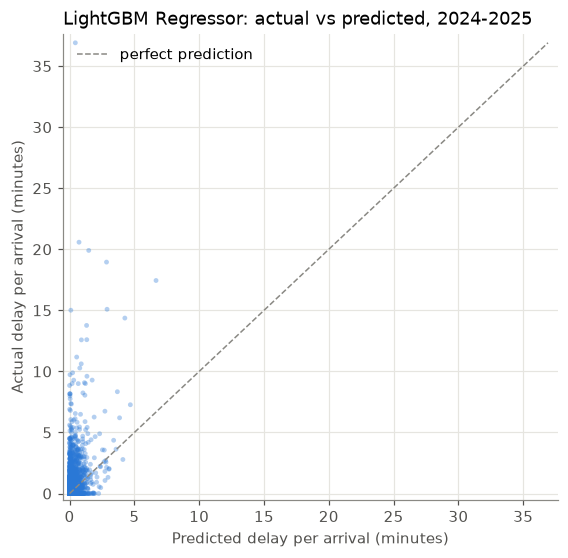

In [43]:
# 11.4 actual versus predicted on 2024-2025
largest_value = max(test_values.max(), test_prediction.max())

fig, ax = plt.subplots(figsize=(5.8, 5.5))
ax.scatter(test_prediction, test_values, s=10, alpha=0.35, color=MODEL_COLOR, edgecolors="none")
ax.plot([0, largest_value], [0, largest_value], linestyle="--", color=REFERENCE_COLOR, linewidth=1,
        label="perfect prediction")
ax.set_xlabel("Predicted delay per arrival (minutes)")
ax.set_ylabel("Actual delay per arrival (minutes)")
ax.set_title("LightGBM Regressor: actual vs predicted, 2024-2025", loc="left")
ax.set_xlim(-0.5, largest_value * 1.02)
ax.set_ylim(-0.5, largest_value * 1.02)
ax.set_axisbelow(True)
ax.legend(frameon=False, loc="upper left")
plt.show()

Most predictions are below about 3 minutes and the highest is about 6.7, while actual values reach 37, so as with Ridge severe days are never predicted as severe. Calm days are pushed closer to zero than with Ridge.

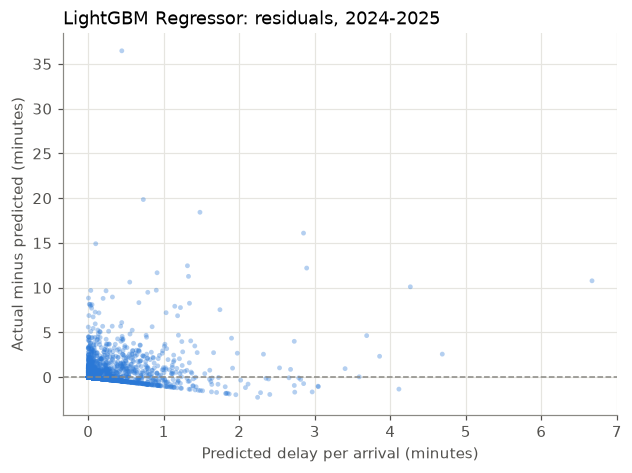

Days where the model was too low by more than 5 minutes:  49
Days where the model was too high by more than 5 minutes: 0


In [44]:
# 11.5 residuals (actual minus predicted) against the prediction
residuals = test_values - test_prediction

fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.scatter(test_prediction, residuals, s=10, alpha=0.35, color=MODEL_COLOR, edgecolors="none")
ax.axhline(0, color=REFERENCE_COLOR, linestyle="--", linewidth=1)
ax.set_xlabel("Predicted delay per arrival (minutes)")
ax.set_ylabel("Actual minus predicted (minutes)")
ax.set_title("LightGBM Regressor: residuals, 2024-2025", loc="left")
ax.set_axisbelow(True)
plt.show()

print(f"Days where the model was too low by more than 5 minutes:  {(residuals > 5).sum()}")
print(f"Days where the model was too high by more than 5 minutes: {(residuals < -5).sum()}")

The diagonal band at the bottom left is calm days (residual equals minus the prediction). 49 days were under-predicted by more than 5 minutes and none over-predicted by that much.

In [45]:
# 11.6 does performance hold in both test years?
test_years = test_days["year"].to_numpy()
year_rows = []
for year in [2024, 2025]:
    in_year = test_years == year
    year_rows.append({
        "year": year,
        "rows": int(in_year.sum()),
        "mean_actual": test_values[in_year].mean(),
        "model_MAE": mean_absolute_error(test_values[in_year], test_prediction[in_year]),
        "benchmark_28d_MAE": mean_absolute_error(test_values[in_year], test_rolling[in_year]),
        "always_zero_MAE": test_values[in_year].mean(),
        "model_RMSE": np.sqrt(mean_squared_error(test_values[in_year], test_prediction[in_year])),
        "benchmark_28d_RMSE": np.sqrt(mean_squared_error(test_values[in_year], test_rolling[in_year])),
    })
pd.DataFrame(year_rows).round(3)

,year,rows,mean_actual,model_MAE,benchmark_28d_MAE,always_zero_MAE,model_RMSE,benchmark_28d_RMSE
0,2024,4391,0.230,0.225,0.330,0.230,1.061,1.100
1,2025,4380,0.184,0.175,0.266,0.184,0.818,0.863


The MAE advantage over always zero is small in both years (0.225 vs 0.230 in 2024, 0.175 vs 0.184 in 2025). RMSE beats the 28-day average in both years (1.061 vs 1.100, 0.818 vs 0.863).

## 12. Results by airport

`always_zero_MAE` equals the airport's mean delay, and `bias` is mean prediction minus mean actual. R² is left empty where an airport had no delay in 2024–2025. Neighbouring days are correlated, so a single bad week can dominate an airport's figures.

In [46]:
# 12.1 one row per airport for 2024-2025
test_results = test_days[["airport_icao", "airport_name", "date", "year"]].copy()
test_results["actual"] = test_values
test_results["prediction"] = test_prediction
test_results["prediction_unclipped"] = test_prediction_raw
test_results["benchmark_28d"] = test_rolling

airport_rows = []
for airport, group in test_results.groupby("airport_icao"):
    row = {
        "airport": airport,
        "name": group["airport_name"].iloc[0],
        "days": len(group),
        "positive_days": int((group["actual"] > 0).sum()),
        "mean_actual": group["actual"].mean(),
        "mean_prediction": group["prediction"].mean(),
        "model_MAE": mean_absolute_error(group["actual"], group["prediction"]),
        "benchmark_28d_MAE": mean_absolute_error(group["actual"], group["benchmark_28d"]),
        "always_zero_MAE": group["actual"].mean(),
        "model_RMSE": np.sqrt(mean_squared_error(group["actual"], group["prediction"])),
        "benchmark_28d_RMSE": np.sqrt(mean_squared_error(group["actual"], group["benchmark_28d"])),
        "R2": np.nan,
    }
    if group["actual"].nunique() > 1:
        row["R2"] = r2_score(group["actual"], group["prediction"])
    row["bias"] = row["mean_prediction"] - row["mean_actual"]
    airport_rows.append(row)

airport_metrics = pd.DataFrame(airport_rows).sort_values("mean_actual", ascending=False)
airport_metrics.round(3)

,airport,name,days,positive_days,mean_actual,mean_prediction,model_MAE,benchmark_28d_MAE,always_zero_MAE,model_RMSE,benchmark_28d_RMSE,R2,bias
1,EDDF,Frankfurt,731,297,1.111,0.364,1.003,1.499,1.111,2.640,2.784,0.085,-0.747
4,EDDK,Cologne-Bonn,731,216,0.473,0.233,0.432,0.619,0.473,0.930,0.983,0.132,-0.241
6,EDDM,Munich,731,214,0.382,0.136,0.364,0.525,0.382,1.036,1.047,0.058,-0.246
8,EDDP,Leipzig-Halle,731,80,0.203,0.057,0.225,0.363,0.203,0.851,0.883,0.047,-0.146
9,EDDS,Stuttgart,731,70,0.201,0.011,0.207,0.353,0.201,0.905,0.898,-0.033,-0.190
5,EDDL,Duesseldorf,731,44,0.084,0.043,0.114,0.158,0.084,0.492,0.509,0.032,-0.041
3,EDDH,Hamburg,731,19,0.025,0.024,0.045,0.048,0.025,0.233,0.232,-0.032,-0.001
11,EDDW,Bremen,731,1,0.004,0.001,0.006,0.009,0.004,0.121,0.122,-0.023,-0.003
7,EDDN,Nuremberg,731,1,0.002,0.000,0.002,0.003,0.002,0.041,0.041,-0.001,-0.001
2,EDDG,Muenster-Osnabrueck,731,1,0.001,0.000,0.001,0.003,0.001,0.037,0.038,-0.001,-0.001


- Frankfurt: actual mean 1.11, predicted 0.36 (bias −0.75), about a third of the actual delay. MAE (1.00) is still better than always zero (1.11), Ridge (1.30) and the 28-day average (1.50).
- Cologne-Bonn and Munich are each under-predicted by about 0.24.
- Stuttgart: mean prediction 0.011 against an actual 0.20, similar to the classifiers rarely raising alerts there.
- At the quiet airports predictions are essentially zero, which gives near-perfect MAE.

## 13. Interpretation

Gain importance is measured on training data and favours inputs with many distinct values. Permutation importance on 2023 uses RMSE, as in notebook 05, so the two regression models are compared on the same basis; it is descriptive only. Importance shows how much an input is used, not the direction of its effect or a cause of delay.

In [47]:
# 13.1 gain importance from training (share of the total gain)
gain = final_model.booster_.feature_importance(importance_type="gain")
splits = final_model.booster_.feature_importance(importance_type="split")
gain_importance = pd.DataFrame({
    "feature": X_train.columns,
    "gain_share_percent": 100 * gain / gain.sum(),
    "times_used_in_splits": splits,
}).sort_values("gain_share_percent", ascending=False)
gain_importance.head(12).round(2)

,feature,gain_share_percent,times_used_in_splits
34,delay_per_arrival_mean_28d,38.72,1152
28,arrivals_lag7,6.68,1244
20,vis_min_m,5.21,1110
0,airport_icao,3.93,508
24,thunder_hours,3.75,253
33,delay_per_arrival_mean_7d,3.66,853
27,arrivals_lag1,3.30,1195
14,gust_max_ms,2.81,1105
4,doy_cos,2.63,1027
3,doy_sin,2.49,1284


- The 28-day mean delay accounts for 39% of total gain.
- Next are arrivals a week earlier (6.7%), minimum visibility (5.2%), airport (3.9%), thunderstorm hours (3.8%) and the 7-day mean delay (3.7%).
- Many weather inputs contribute about 2–3% each.

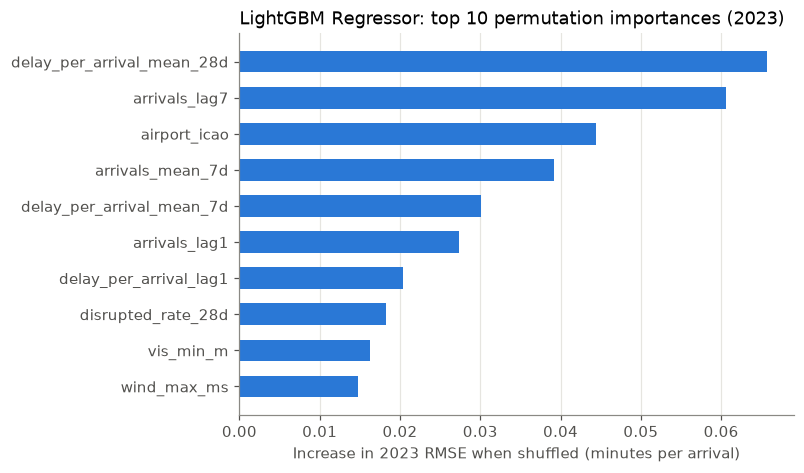

,feature,RMSE_increase_mean,RMSE_increase_std
34,delay_per_arrival_mean_28d,0.0657,0.0065
28,arrivals_lag7,0.0607,0.0056
0,airport_icao,0.0444,0.0077
29,arrivals_mean_7d,0.0392,0.0044
33,delay_per_arrival_mean_7d,0.0301,0.0025
27,arrivals_lag1,0.0274,0.0069
30,delay_per_arrival_lag1,0.0204,0.0010
35,disrupted_rate_28d,0.0182,0.0016
20,vis_min_m,0.0163,0.0052
13,wind_max_ms,0.0147,0.0021


In [48]:
# 13.2 permutation importance on 2023 (increase in RMSE when a column is shuffled)
from sklearn.inspection import permutation_importance

permutation = permutation_importance(
    final_model, X_calibrate, y_calibrate,
    scoring="neg_root_mean_squared_error", n_repeats=5, random_state=RANDOM_SEED,
)
permutation_table = pd.DataFrame({
    "feature": X_calibrate.columns,
    "RMSE_increase_mean": permutation.importances_mean,
    "RMSE_increase_std": permutation.importances_std,
}).sort_values("RMSE_increase_mean", ascending=False)

top_permutation = permutation_table.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.barh(top_permutation["feature"], top_permutation["RMSE_increase_mean"], color=MODEL_COLOR, height=0.6)
ax.set_xlabel("Increase in 2023 RMSE when shuffled (minutes per arrival)")
ax.set_title("LightGBM Regressor: top 10 permutation importances (2023)", loc="left")
ax.grid(axis="y", visible=False)
ax.set_axisbelow(True)
plt.show()

permutation_table.head(10).round(4)

The largest increases in 2023 RMSE come from the 28-day mean delay (+0.066), arrivals a week earlier (+0.061), airport (+0.044), 7-day mean arrivals (+0.039) and the 7-day mean delay (+0.030). Minimum visibility (+0.016) and maximum wind (+0.015) are the strongest weather inputs. LightGBM relies mainly on recent traffic and delay levels, whereas Ridge relied on yesterday's delays and gave thunderstorm and snow/ice inputs large weights; the measures are not identical, so this is only a rough comparison.

In [49]:
# 13.3 the ten test days with the largest absolute errors (description only)
test_results["absolute_error"] = (test_results["actual"] - test_results["prediction"]).abs()
largest_errors = test_results.sort_values("absolute_error", ascending=False).head(10)
largest_errors = largest_errors.merge(
    test_days[["airport_icao", "date", "arrivals", "delay_weather_min", "delay_atc_capacity_min",
               "delay_atc_staffing_min", "delay_aerodrome_capacity_min", "thunder_hours", "gust_max_ms"]],
    on=["airport_icao", "date"],
)
largest_errors["date"] = largest_errors["date"].dt.date
largest_errors[[
    "airport_icao", "date", "actual", "prediction", "benchmark_28d", "arrivals",
    "delay_weather_min", "delay_atc_capacity_min", "delay_atc_staffing_min", "delay_aerodrome_capacity_min",
    "thunder_hours", "gust_max_ms",
]].round(2)

,airport_icao,date,actual,prediction,benchmark_28d,arrivals,delay_weather_min,delay_atc_capacity_min,delay_atc_staffing_min,delay_aerodrome_capacity_min,thunder_hours,gust_max_ms
0,EDDF,2024-11-19,36.91,0.44,3.15,522.0,0.0,0.0,0.0,19266.0,0.0,20.1
1,EDDF,2024-11-12,20.58,0.73,2.56,546.0,0.0,0.0,0.0,11237.0,0.0,8.9
2,EDDF,2025-07-27,19.91,1.48,2.01,654.0,13020.0,0.0,0.0,0.0,0.0,10.7
3,EDDF,2024-01-17,18.95,2.85,1.00,183.0,3468.0,0.0,0.0,0.0,0.0,5.4
4,EDDF,2024-07-25,15.01,0.10,1.05,543.0,0.0,0.0,0.0,0.0,0.0,7.0
5,EDDF,2025-01-05,13.77,1.31,1.25,470.0,5500.0,0.0,0.0,0.0,0.0,7.7
6,EDDF,2025-07-25,15.09,2.89,1.42,659.0,9943.0,0.0,0.0,0.0,0.0,13.5
7,EDDF,2025-06-15,12.58,0.91,1.38,682.0,8581.0,0.0,0.0,0.0,0.0,10.6
8,EDDP,2024-06-18,12.60,1.33,0.53,134.0,1688.0,0.0,0.0,0.0,0.0,13.2
9,EDDF,2024-10-28,17.44,6.67,0.65,585.0,10205.0,0.0,0.0,0.0,0.0,6.5


Mostly the same Frankfurt days top the list as for Ridge, all under-predicted.
- 19 November 2024 (aerodrome capacity, 36.9 minutes): predicted 0.44, lower than Ridge's 1.6.
- 28 October 2024 received the highest prediction in the test period (6.7) against an actual 17.4.

Capacity reductions, runway or airspace restrictions and the hourly timing of weather, which would explain these days, are not in the dataset.

## 14. Saving outputs

Saves the frozen model, clipping rule, predictor list, airport category list, settings and versions to `outputs/06_lightgbm_regression/model.joblib`, together with the test predictions, test metrics, airport metrics and tuning results as CSV, then reloads the model as a check. Inputs must be prepared with the section 5 helper.

In [50]:
# 14.1 save everything needed to reuse and check this model
import joblib

OUTPUT_DIR = PROJECT_ROOT / "outputs" / "06_lightgbm_regression"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

saved_model = {
    "model": final_model,
    "clip_predictions_at_zero": clip_predictions,
    "predictor_columns": predictor_columns,
    "airport_categories": airport_categories,
    "settings": {"objective": chosen_objective, "num_leaves": best_num_leaves, "min_child_samples": best_min_child_samples, "trees": final_model.n_estimators, "random_seed": RANDOM_SEED},
    "training_years": "2014-2021",
    "description": "LightGBM regressor; airport_icao must be a pandas Categorical with airport_categories, other inputs float64 with NaN for missing",
    "versions": {"python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__,
                 "scikit-learn": sklearn.__version__, "lightgbm": lgb.__version__},
}
joblib.dump(saved_model, OUTPUT_DIR / "model.joblib")

test_metrics.loc[test_metrics["rule"] == "LightGBM Regressor", "select_2022_MAE"] = mean_absolute_error(y_select, final_select_prediction)

test_results.to_csv(OUTPUT_DIR / "test_predictions_2024_2025.csv", index=False)
test_metrics.to_csv(OUTPUT_DIR / "test_metrics.csv", index=False)
airport_metrics.to_csv(OUTPUT_DIR / "airport_metrics.csv", index=False)
tuning_results.to_csv(OUTPUT_DIR / "tuning_results.csv", index=False)
objective_results.to_csv(OUTPUT_DIR / "objective_results.csv", index=False)

for saved_file in sorted(OUTPUT_DIR.iterdir()):
    print(saved_file.name)

airport_metrics.csv
model.joblib
objective_results.csv
test_metrics.csv
test_predictions_2024_2025.csv
tuning_results.csv


In [51]:
# 14.2 reload the saved model and check it reproduces the saved predictions
reloaded = joblib.load(OUTPUT_DIR / "model.joblib")
reloaded_prediction = reloaded["model"].predict(X_test)
if reloaded["clip_predictions_at_zero"]:
    reloaded_prediction = np.clip(reloaded_prediction, 0, None)
print("Reloaded model gives identical test predictions:", np.allclose(reloaded_prediction, test_prediction))

Reloaded model gives identical test predictions: True


The reloaded model reproduces the test predictions exactly. Reuse requires the airport column as a category built from the saved `airport_categories` list.

## Comparison with Ridge regression

Reads the saved results of notebook 05 (`outputs/05_ridge_regression`), so notebook 05 must be run first.

In [52]:
# 14.3 confirm both notebooks scored the same rows, then build the comparison table
ridge_folder = PROJECT_ROOT / "outputs" / "05_ridge_regression"
ridge_predictions = pd.read_csv(ridge_folder / "test_predictions_2024_2025.csv")
ridge_metrics = pd.read_csv(ridge_folder / "test_metrics.csv")

same_rows = (
    list(ridge_predictions["airport_icao"]) == list(test_results["airport_icao"])
    and list(pd.to_datetime(ridge_predictions["date"])) == list(test_results["date"])
    and np.allclose(ridge_predictions["actual"], test_results["actual"])
)
print("Both notebooks evaluated the same", len(test_results), "airport-days with the same targets:", same_rows)

is_ridge_row = ridge_metrics["rule"].str.startswith("Ridge Regression")
is_lightgbm_row = test_metrics["rule"].str.startswith("LightGBM")
comparison = pd.concat([
    ridge_metrics[is_ridge_row],
    test_metrics[is_lightgbm_row],
    test_metrics[~is_lightgbm_row],
])
regression_comparison = comparison[["rule", "select_2022_MAE", "MAE", "RMSE", "R2", "mean_prediction"]].reset_index(drop=True)
regression_comparison.to_csv(OUTPUT_DIR / "regression_comparison.csv", index=False)
regression_comparison.round(4)

Both notebooks evaluated the same 8771 airport-days with the same targets: True


,rule,select_2022_MAE,MAE,RMSE,R2,mean_prediction
0,Ridge Regression,0.2928,0.2904,0.9573,0.1413,0.2065
1,Ridge Regression without clipping (reference o...,NaN,0.3244,0.9595,0.1373,0.1725
2,LightGBM Regressor,0.1734,0.1999,0.9472,0.1593,0.0725
3,LightGBM Regressor without clipping (reference...,NaN,0.1999,0.9472,0.1593,0.0725
4,previous 28-day average,NaN,0.2984,0.9887,0.0840,0.2077
5,training median (= zero delay),NaN,0.2073,1.0536,-0.0403,0.0000
6,training mean,NaN,0.3594,1.0331,-0.0002,0.1923


Both notebooks scored the same 8,771 airport-days with the same targets.

In [53]:
# 14.4 the two models by airport, side by side (2024-2025)
ridge_airports = pd.read_csv(ridge_folder / "airport_metrics.csv")
airport_comparison = ridge_airports[["airport", "name", "days", "positive_days", "mean_actual", "model_MAE", "model_RMSE"]].rename(
    columns={"model_MAE": "ridge_MAE", "model_RMSE": "ridge_RMSE"}
)
airport_comparison = airport_comparison.merge(
    airport_metrics[["airport", "model_MAE", "model_RMSE", "benchmark_28d_MAE", "always_zero_MAE"]].rename(
        columns={"model_MAE": "lightgbm_MAE", "model_RMSE": "lightgbm_RMSE"}
    ),
    on="airport",
)
airport_comparison.to_csv(OUTPUT_DIR / "airport_comparison.csv", index=False)
airport_comparison.round(3)

,airport,name,days,positive_days,mean_actual,ridge_MAE,ridge_RMSE,lightgbm_MAE,lightgbm_RMSE,benchmark_28d_MAE,always_zero_MAE
0,EDDF,Frankfurt,731,297,1.111,1.302,2.666,1.003,2.640,1.499,1.111
1,EDDK,Cologne-Bonn,731,216,0.473,0.532,0.933,0.432,0.930,0.619,0.473
2,EDDM,Munich,731,214,0.382,0.487,1.000,0.364,1.036,0.525,0.382
3,EDDP,Leipzig-Halle,731,80,0.203,0.316,0.876,0.225,0.851,0.363,0.203
4,EDDS,Stuttgart,731,70,0.201,0.297,0.883,0.207,0.905,0.353,0.201
5,EDDL,Duesseldorf,731,44,0.084,0.183,0.494,0.114,0.492,0.158,0.084
6,EDDH,Hamburg,731,19,0.025,0.141,0.301,0.045,0.233,0.048,0.025
7,EDDW,Bremen,731,1,0.004,0.074,0.227,0.006,0.121,0.009,0.004
8,EDDN,Nuremberg,731,1,0.002,0.022,0.085,0.002,0.041,0.003,0.002
9,EDDG,Muenster-Osnabrueck,731,1,0.001,0.046,0.172,0.001,0.037,0.003,0.001


- MAE: LightGBM is lower at every airport with any delay, mainly because it predicts close to zero on most days.
- RMSE: the models are close. LightGBM is lower at Frankfurt (2.64 vs 2.67), Cologne-Bonn (0.930 vs 0.933), Düsseldorf (0.492 vs 0.494), Leipzig-Halle, Hamburg and the quiet airports; Ridge is lower at Munich (1.000 vs 1.036) and Stuttgart (0.883 vs 0.905).

## Conclusion

| 2024–2025 | Ridge | LightGBM (Tweedie) | Always zero | 28-day average |
|---|---|---|---|---|
| MAE (main metric) | 0.290 | 0.200 | 0.207 | 0.298 |
| RMSE | 0.957 | 0.947 | 1.054 | 0.989 |
| R² | 0.14 | 0.16 | | |
| Mean prediction (actual 0.207) | 0.2065 | 0.0725 | 0 | 0.208 |

- On the pre-specified metric (MAE), LightGBM wins and is the only rule that beats always zero, but only by 0.007 minutes per arrival, almost entirely through near-zero predictions on the 89% of calm days.
- On RMSE the two models are very close (0.947 vs 0.957) and both beat every benchmark.
- Neither model handles severe days well. R² of 0.14–0.16 leaves most day-to-day variation unexplained, no prediction exceeds about 7 minutes while actual values reach 37, and on positive-delay days Ridge is more accurate (MAE 1.48 vs 1.61).
- The metric choice mattered. Selecting by MAE on a mostly-zero target rewards predicting about zero, which is how Tweedie was selected (section 10) and why LightGBM's predictions sum to about a third of the actual delay, while Ridge's sum to almost the correct total. For an expected-delay use, such as total delay minutes over a season, Ridge would be more useful despite its worse MAE, and RMSE or Tweedie deviance would be the more appropriate selection metric. The intended use should be fixed before the metric.
- The extra complexity of LightGBM gives only a marginal RMSE gain; its MAE gain comes mostly from low predictions that a simpler rule could imitate.

Limitations common to both models:
- Observed same-day weather is used as a perfect forecast.
- 2024–2025 was inspected in earlier project work.
- The COVID years 2020–2021 are in the training data.
- Neighbouring days are not independent, so small differences are uncertain.
- The most severe days appear to be driven by information not in the dataset: capacity reductions, aerodrome and ATC constraints, and the hourly timing of weather.

Possible next steps: a two-part model (classifier probability of any delay combined with a model of delay size), a selection metric matched to the intended use and fixed in advance, quantile regression for the tail, day-ahead weather forecasts instead of observed weather, data on capacity regulations, a pre-specified training window excluding 2020–2021, and a block bootstrap for uncertainty ranges.